In [15]:
#### This notebook is used to generate noise/outlier detection 

In [16]:
import pandas as pd
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np

# load data
df = pd.read_csv("../heart.csv")

df.head()

df.columns

Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope',
       'HeartDisease'],
      dtype='object')

#### Attempt MAD with very low multiplier (because otherwise no noise is detected)

In [17]:
# use MAD only for continuous variables, preferably the most 
# impactful one towards the target variable
variable = "Cholesterol"

# Calculate the median
median = df[variable].median()

# Calculate MAD
mad = np.median(np.abs(df[variable] - median))

# Define a threshold for noise detection
# adjust the numeric modifier for aggressiveness 
# e.g. try 2.5 or 4.5 etc.
# if the value is too high, you will find no noise (decrease in that case)
threshold = 2.0 * mad

# Detect noise
noise = df[np.abs(df[variable] - median) > threshold]

inliers = df.drop(noise.index)

print("Detected noise using MAD:")
noise

Detected noise using MAD:


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
5,39,M,NAP,120,339,0,Normal,170,N,0.0,Up,0
28,53,F,ATA,113,468,0,Normal,127,N,0.0,Up,0
30,53,M,NAP,145,518,0,Normal,130,N,0.0,Flat,1
45,59,M,NAP,130,318,0,Normal,120,Y,1.0,Flat,0
48,36,M,NAP,112,340,0,Normal,184,N,1.0,Flat,0
...,...,...,...,...,...,...,...,...,...,...,...,...
873,64,M,NAP,140,335,0,Normal,158,N,0.0,Up,1
875,58,F,NAP,120,340,0,Normal,172,N,0.0,Up,0
895,57,M,ASY,110,335,0,Normal,143,Y,3.0,Flat,1
900,58,M,ASY,114,318,0,ST,140,N,4.4,Down,1


In [18]:
print(len(inliers))
print(len(noise))

671
247


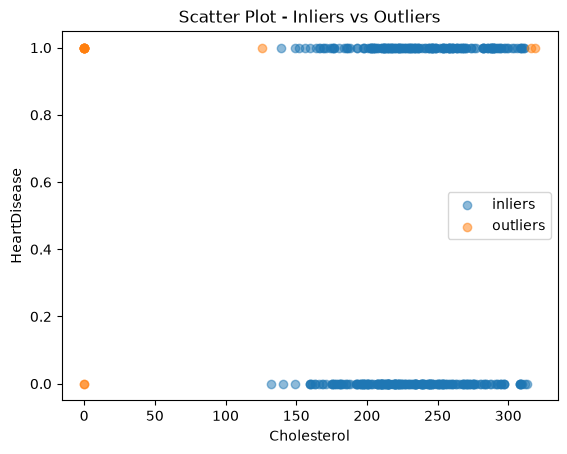

In [19]:
import matplotlib.pyplot as plt

variable = "Cholesterol"
target = "HeartDisease"

# if you want to reduce the number of points visualized
# sample a small amount of points, for example 300-500
inliers_sample = inliers.sample(400)
outliers_sample = noise.sample(14)

plt.scatter(inliers_sample[variable], inliers_sample[target], label="inliers", alpha=0.5)
plt.scatter(outliers_sample[variable], outliers_sample[target], label="outliers", alpha=0.5)

plt.xlabel(variable)
plt.ylabel(target)

plt.title("Scatter Plot - Inliers vs Outliers")
plt.legend()
plt.show()

#### Isolation Forest can be used throughout the dataset

In [20]:
from sklearn.ensemble import IsolationForest
iso = IsolationForest(contamination=0.075) 



In [21]:
# this just converts the value of column to 0 or 1
# factorize in pandas works too, but only one column at a time
from sklearn.preprocessing import LabelEncoder
variables = ['ExerciseAngina']
encoder = LabelEncoder()
df[variables] = df[variables].apply(encoder.fit_transform)

In [22]:
cut_mapper = {'Down': 1, 'Flat': 2,'Up': 3}
df['ST_Slope'] = df['ST_Slope'].map(cut_mapper)

In [23]:
# this makes multiple columns with the variable (Separate for yes/no)
from sklearn.preprocessing import OneHotEncoder
variables = ['Sex', 'ChestPainType', 'RestingECG']

# use encoder
encoder = OneHotEncoder(sparse_output=False).set_output(transform="pandas")
one_hot_encoded = encoder.fit_transform(df[variables]).astype(int)
df = pd.concat([df,one_hot_encoded],axis=1).drop(columns=variables)

In [24]:
# fit isolation forest
y_pred = iso.fit_predict(df)

# separate outliers and inliers into separate DataFrames
outliers = df[y_pred != 1]
inliers = df[y_pred == 1]

print(f"Inliers: {len(inliers)}")
print(f"Outliers: {len(outliers)}")

Inliers: 849
Outliers: 69


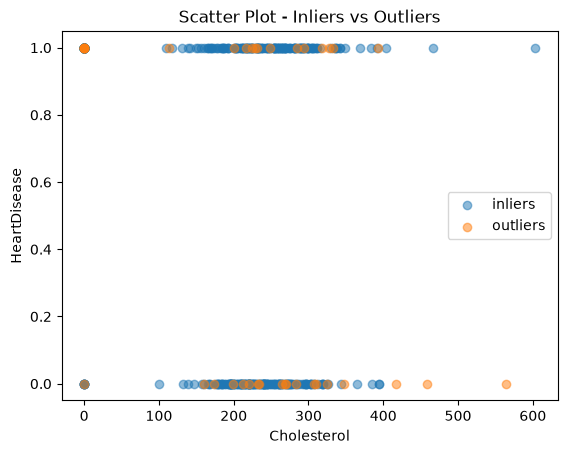

In [25]:
import matplotlib.pyplot as plt

# change the variable if you want to inspect this from other point of views
variable = "Cholesterol"
target = "HeartDisease"

# if you want to reduce the number of points visualized
# sample a small amount of points, for example 300-500
inliers_sample = inliers.sample(400)
outliers_sample = outliers.sample(38)

plt.scatter(inliers_sample[variable], inliers_sample[target], label="inliers", alpha=0.5)
plt.scatter(outliers_sample[variable], outliers_sample[target], label="outliers", alpha=0.5)

plt.xlabel(variable)
plt.ylabel(target)

plt.title("Scatter Plot - Inliers vs Outliers")
plt.legend()
plt.show()

<Axes: >

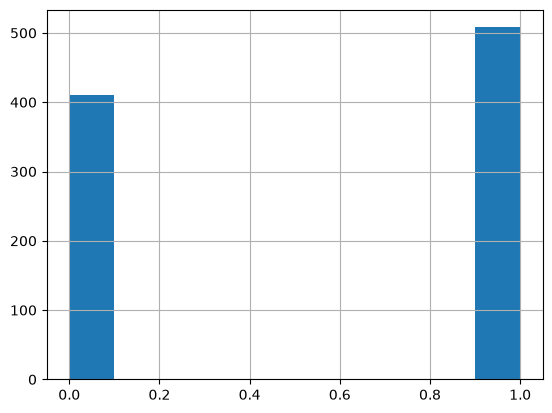

In [26]:
df['HeartDisease'].hist()